# Studi Kasus IMV Laboratory: Background Video Call yang Rapi
### Fill in the blank (tingkat sulit): KUNCI JAWABAN, versi upload gambar

**Situasi:** kamu ingin mengganti background video call dengan foto kampus. Fotomu diambil di depan latar polos berwarna, tapi hasil chroma key awalnya kasar: ada bintik noise di background dan tepi badan bergerigi.

| Tahap | Misi | Konsep |
|---|---|---|
| 1 | Chroma key dasar | HSV, `cv2.inRange`, bitwise, `cv2.add` |
| 2 | Bersihkan bintik | median filter, termasuk membuatnya sendiri tanpa `cv2.medianBlur` |
| 3 | Haluskan tepi | Gaussian blur, alpha blending |
| 4 | Bandingkan dan analisis | evaluasi visual dan angka |
| Bonus | Periksa tepi | `cv2.Canny` |

### Aturan main
1. Ganti setiap `____` dengan kode yang benar. Nomor soal ada di komentar, mis. `# [3]`. Satu baris bisa berisi lebih dari satu blank.
2. Satu blank boleh berupa angka, nama variabel, fungsi, atau ekspresi pendek.
3. Jangan mengubah kode di luar blank, termasuk sel **Cek**.
4. **Dilarang** memakai loop per piksel.
5. Jalankan berurutan dari atas. Lanjut hanya kalau sel Cek sudah lolos.
6. Lolos Cek belum tentu sempurna. Tetap lihat hasil gambarnya.

## 0. Persiapan (sudah lengkap, tinggal jalankan)

In [1]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt


def show(images, titles, cols=3, size=(4, 4)):
    """Citra 2D ditampilkan grayscale (0-255), citra 3D dianggap sudah RGB."""
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size[0], rows * size[1]))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis('off')
    for ax, im, title in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        else:
            ax.imshow(im, interpolation='nearest')
        ax.set_title(title, fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()


# False: sel Cek hanya memberi PERINGATAN lalu lanjut. True: berhenti dengan error.
MODE_KETAT = False


def cek(kondisi, pesan):
    """Pengganti assert. Mengembalikan True kalau lolos."""
    if kondisi:
        return True
    if MODE_KETAT:
        raise AssertionError(pesan)
    print('PERINGATAN:', pesan)
    return False


def ganjil(k):
    """Bulatkan ke bilangan ganjil positif (syarat kernel median dan Gaussian)."""
    return max(1, int(k)) | 1


def rgb(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

### 0.1 Siapkan Gambarmu

1. Cari atau potret **satu foto orang atau objek di depan latar polos berwarna**. Hijau paling disarankan, biru juga bisa. Hindari latar merah, putih, abu-abu, dan hitam, serta foto yang bajunya mirip warna latar.
2. Taruh file di **folder yang sama dengan notebook ini** (di Colab: upload lewat panel Files).
3. Ganti `FOTO_PATH` sesuai nama filemu, lengkap dengan ekstensinya.
4. (Opsional) taruh `background.jpg` sebagai foto kampus. Kalau tidak ada, dipakai gambar buatan.

> Foto dengan latar dinding atau kamar biasa **tidak cocok** untuk chroma key.

Ukuran gambar yang diproses: (1334, 960, 3)


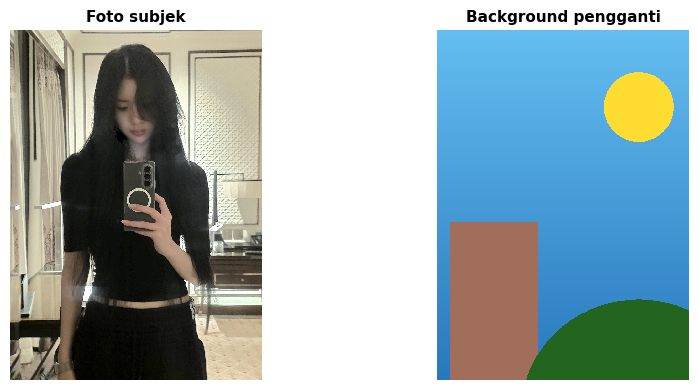

In [2]:
FOTO_PATH = 'h2hjuun.jpg'    # <-- ganti dengan nama file gambarmu
BG_PATH = 'background.jpg'       # foto kampus
LEBAR_MAKS = 960                 # gambar yang lebih lebar akan diperkecil

EKSTENSI = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')


def baca_gambar(path):
    """Seperti cv2.imread, tetapi aman untuk nama file berkarakter non-ASCII."""
    if not os.path.isfile(path):
        return None
    data = np.fromfile(path, np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None


frame = baca_gambar(FOTO_PATH)
if frame is None:
    daftar = sorted((f for f in os.listdir('.')
                     if f.lower().endswith(EKSTENSI) and f.lower() != os.path.basename(BG_PATH).lower()),
                    key=os.path.getmtime, reverse=True)
    for nama_file in daftar:
        frame = baca_gambar(nama_file)
        if frame is not None:
            print(f"PERINGATAN: '{FOTO_PATH}' tidak bisa dibaca. Dipakai gambar terbaru: '{nama_file}'.")
            FOTO_PATH = nama_file
            break
if frame is None:
    raise FileNotFoundError(f"Tidak ada gambar yang bisa dibaca di folder {os.getcwd()}. "
                            'Taruh foto di folder tersebut lalu jalankan ulang sel ini.')

if frame.shape[1] > LEBAR_MAKS:
    skala = LEBAR_MAKS / frame.shape[1]
    frame = cv2.resize(frame, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
print('Ukuran gambar yang diproses:', frame.shape)


def buat_background(h, w):
    bg = np.zeros((h, w, 3), np.uint8)
    for y in range(h):
        t = y / h
        bg[y] = (int(240 - 50 * t), int(190 - 70 * t), int(100 - 60 * t))
    cv2.circle(bg, (int(0.80 * w), int(0.22 * h)), int(0.10 * h), (50, 220, 255), -1)
    cv2.rectangle(bg, (int(0.05 * w), int(0.55 * h)), (int(0.40 * w), h), (90, 110, 160), -1)
    cv2.ellipse(bg, (int(0.80 * w), int(1.10 * h)), (int(0.47 * w), int(0.33 * h)),
                0, 0, 360, (30, 100, 35), -1)
    return bg


h, w = frame.shape[:2]
bg_img = baca_gambar(BG_PATH)
bg_img = buat_background(h, w) if bg_img is None else cv2.resize(bg_img, (w, h))

# Semua citra tetap BGR selama diproses. Ubah ke RGB HANYA saat ditampilkan.
show([rgb(frame), rgb(bg_img)], ['Foto subjek', 'Background pengganti'], cols=2, size=(5, 4))

### 0.2 Atur Kotak Sampel
Pengganti kunci jawaban: kamu yang memberi tahu komputer contoh area yang benar.

Tiap kotak ditulis sebagai `(x, y, lebar, tinggi)` dalam **pecahan ukuran gambar** (0 sampai 1). `x, y` adalah pojok kiri atas kotak. Contoh: `(0.5, 0.5, 0.1, 0.1)` mulai dari tengah gambar.

Ubah angkanya, jalankan ulang sel, sampai:
- **kotak kuning hanya berisi latar** (sebaiknya di dua sisi, termasuk bagian yang gelap),
- **kotak merah hanya berisi subjek**.

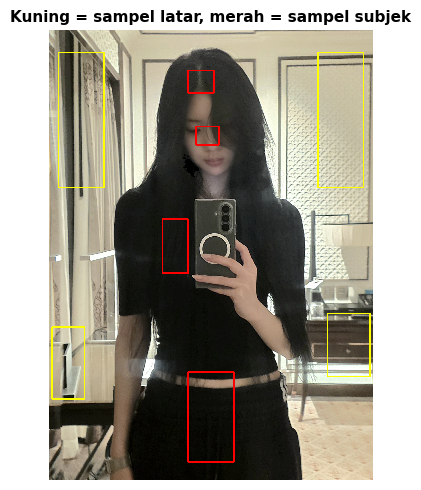

In [3]:
PANDUAN = {'latar':   [(0.03, 0.05, 0.14, 0.30), (0.83, 0.05, 0.14, 0.30),
                       (0.86, 0.63, 0.13, 0.14),     # perabot kanan
                       (0.01, 0.66, 0.10, 0.16)],    # perabot kiri
           'subjek': [(0.43, 0.76, 0.14, 0.20),     # celana
                      (0.35, 0.42, 0.08, 0.12),     # baju
                      (0.455, 0.215, 0.07, 0.04),   # wajah
                      (0.43, 0.09, 0.08, 0.05)]}    # rambut

# Perkiraan area yang memuat seluruh subjek (hanya dipakai metode GrabCut)
AREA_SUBJEK = (0.15, 0.04, 0.70, 0.96)
WARNA = {'latar': (0, 255, 255), 'subjek': (0, 0, 255)}


def ke_piksel(kotak, tinggi, lebar):
    # Kotak yang keluar gambar dipotong, dan ukurannya minimal 1 piksel
    x, y, bw, bh = kotak
    x0 = int(np.clip(x * lebar, 0, lebar - 1))
    y0 = int(np.clip(y * tinggi, 0, tinggi - 1))
    x1 = int(np.clip((x + bw) * lebar, x0 + 1, lebar))
    y1 = int(np.clip((y + bh) * tinggi, y0 + 1, tinggi))
    return x0, y0, x1 - x0, y1 - y0


roi = {nama: [ke_piksel(k, h, w) for k in daftar] for nama, daftar in PANDUAN.items()}


def potong(citra, daftar_kotak):
    # Gabungkan semua piksel dari kotak-kotak sampel jadi satu kolom
    bagian = [citra[y:y + bh, x:x + bw].reshape(-1, 1, *citra.shape[2:])
              for x, y, bw, bh in daftar_kotak]
    return np.concatenate(bagian)


pratinjau = frame.copy()
for nama, daftar in roi.items():
    for x, y, bw, bh in daftar:
        cv2.rectangle(pratinjau, (x, y), (x + bw, y + bh), WARNA[nama], 3)
show([rgb(pratinjau)], ['Kuning = sampel latar, merah = sampel subjek'], cols=1, size=(7, 5))

---
## Tahap 1: Chroma Key Dasar

**Misi**
- Buat `mask` dengan konvensi **255 = background (latar)** dan **0 = subjek**. Ingat konvensi ini sampai akhir notebook.
- Temukan batas HSV untuk **latarmu sendiri**. Tidak ada angka yang pasti benar.
- Buat fungsi komposit keras (tanpa transisi) yang digabung dengan `cv2.add`.

### 1A. Kenali warna latarmu
Lihat sebaran H, S, V pada sampel latar, bandingkan dengan sampel subjek.

**Latar tidak polos?** Dengan `METODE = 'auto'` (sel 1D), notebook beralih ke **GrabCut** jika latar sampel tidak cukup berwarna untuk chroma key. Pastikan kotak sampel dan `AREA_SUBJEK` sesuai dengan fotomu, karena GrabCut bergantung padanya.

In [4]:
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)                # [1]

for nama in ['latar', 'subjek']:
    piksel = potong(hsv, roi[nama]).reshape(-1, 3)
    p5, p50, p95 = np.percentile(piksel, [5, 50, 95], axis=0)   # [2] satu angka untuk tiap channel
    print(f'{nama:7s} H,S,V  p5={p5.astype(int)}  median={p50.astype(int)}  p95={p95.astype(int)}')

latar   H,S,V  p5=[16 20 54]  median=[ 24  44 190]  p95=[ 40  78 221]
subjek  H,S,V  p5=[13 21  6]  median=[36 81 16]  p95=[ 50 213 128]


### 1B. Tentukan batas HSV
Isi batas awal berdasarkan angka di atas. Beri kelonggaran, karena sampelmu tidak mewakili seluruh latar.

In [5]:
lower_hsv = np.array([35, 50, 50])                  # [3] H, S, V minimum
upper_hsv = np.array([85, 255, 255])                        # [4] H maksimum


def buat_mask(frame_bgr, lower, upper):
    # Kembalikan mask: 255 = background.
    citra_hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV)
    lo, hi = np.array(lower).copy(), np.array(upper).copy()
    lo[1:], hi[1:] = np.minimum(lo[1:], hi[1:]), np.maximum(lo[1:], hi[1:])   # S, V terbalik: ditukar
    if lo[0] <= hi[0]:
        return cv2.inRange(citra_hsv, lo, hi)               # [5]
    # H min > H max: rentang melingkar (mis. merah, 170 sampai 10)
    atas = cv2.inRange(citra_hsv, lo, np.array([179, hi[1], hi[2]]))
    bawah = cv2.inRange(citra_hsv, np.array([0, lo[1], lo[2]]), hi)
    return cv2.bitwise_or(atas, bawah)

### 1C. Eksplorasi dengan slider (opsional, sangat disarankan)
Hanya untuk VSCode atau Jupyter lokal dengan `opencv-python` (tidak jalan di Colab). Set `PAKAI_SLIDER = True`. Geser 6 slider sambil melihat mask secara langsung. Fungsi ini memakai `buat_mask` buatanmu, jadi blank [5] harus benar dulu. Tekan **q** untuk selesai, lalu **salin angka yang tercetak** ke blank [3], [4], dan `upper_hsv`.

Coba amati: apa yang terjadi kalau rentang H dipersempit? Kalau S minimum diturunkan ke 0?

In [6]:
PAKAI_SLIDER = False


def setel_hsv(frame_bgr, lower, upper):
    jendela = 'Setel HSV, tekan q untuk selesai'
    cv2.namedWindow(jendela)
    nama = ['H min', 'S min', 'V min', 'H max', 'S max', 'V max']
    for n, awal, maks in zip(nama, [*lower, *upper], [179, 255, 255] * 2):
        cv2.createTrackbar(n, jendela, int(awal), maks, lambda v: None)
    while True:
        nilai = [cv2.getTrackbarPos(n, jendela) for n in nama]
        lo, hi = np.array(nilai[:3]), np.array(nilai[3:])
        m = buat_mask(frame_bgr, lo, hi)
        tampil = np.hstack([frame_bgr, cv2.cvtColor(m, cv2.COLOR_GRAY2BGR)])
        if tampil.shape[1] > 1400:
            tampil = cv2.resize(tampil, None, fx=1400 / tampil.shape[1], fy=1400 / tampil.shape[1])
        cv2.imshow(jendela, tampil)
        if cv2.waitKey(20) & 0xFF == ord('q'):
            break
    cv2.destroyAllWindows()
    cv2.waitKey(1)
    print('lower_hsv =', lo.tolist())
    print('upper_hsv =', hi.tolist())
    return lo, hi


if PAKAI_SLIDER:
    try:
        lower_hsv, upper_hsv = setel_hsv(frame, lower_hsv, upper_hsv)
    except cv2.error as e:
        print('PERINGATAN: slider tidak bisa dibuka di lingkungan ini, batas HSV tetap.', e)

### 1D. Komposit keras

Metode mask: GrabCut
Sampel latar benar: 100.0% | sampel subjek benar: 100.0%


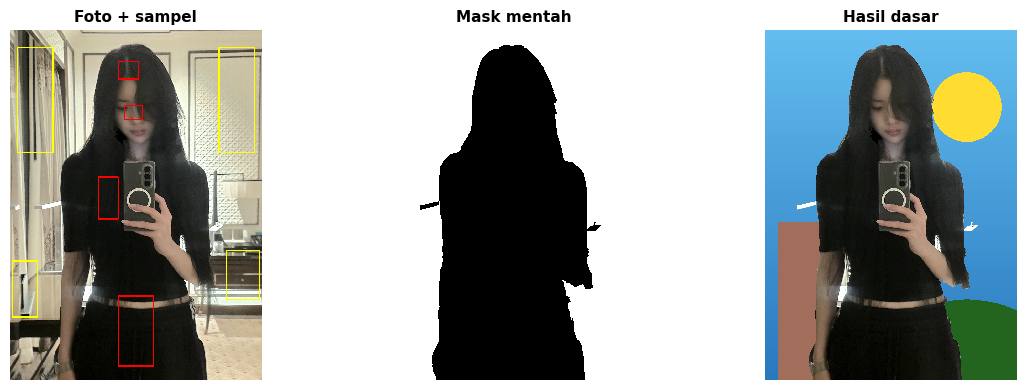

In [7]:
METODE = 'auto'     # 'auto', 'hsv' (chroma key), atau 'grabcut' (latar tidak polos)


def skor_sampel(m):
    latar = np.mean(potong(m, roi['latar']) == 255) * 100
    subjek = np.mean(potong(m, roi['subjek']) == 0) * 100
    return latar, subjek


def batas_dari_sampel(citra_hsv):
    """Perkirakan batas HSV dari kotak latar (untuk latar polos berwarna)."""
    piksel = potong(citra_hsv, roi['latar']).reshape(-1, 3)
    p1, p99 = np.percentile(piksel, [1, 99], axis=0)
    longgar = np.array([8, 40, 50])
    lo = np.clip(p1 - longgar, 0, [179, 255, 255]).astype(int)
    hi = np.clip(p99 + longgar, 0, [179, 255, 255]).astype(int)
    return lo, hi


def latar_cocok_chroma(citra_hsv):
    """True kalau sampel latar cukup jenuh dan warnanya seragam."""
    piksel = potong(citra_hsv, roi['latar']).reshape(-1, 3).astype(np.float32)
    sudut = piksel[:, 0] * (np.pi / 90)                       # H bersifat melingkar
    seragam = np.hypot(np.cos(sudut).mean(), np.sin(sudut).mean())
    return np.median(piksel[:, 1]) >= 80 and seragam >= 0.9


def rapikan_mask(m, luas_lubang=0.01, porsi_min=0.05):
    """Buang potongan subjek yang kecil dan tutup lubang kecil di dalam subjek."""
    n, label, stat, _ = cv2.connectedComponentsWithStats(cv2.bitwise_not(m), connectivity=8)
    if n > 1:
        luas = stat[1:, cv2.CC_STAT_AREA]
        simpan = 1 + np.where(luas >= porsi_min * luas.max())[0]
        m = np.where(np.isin(label, simpan), 0, 255).astype(np.uint8)
    n, label, stat, _ = cv2.connectedComponentsWithStats(m, connectivity=4)
    for i in range(1, n):
        x, y, bw, bh, luas = stat[i]
        di_pinggir = x == 0 or y == 0 or x + bw == m.shape[1] or y + bh == m.shape[0]
        if not di_pinggir and luas < luas_lubang * m.size:
            m[label == i] = 0
    return m


def mask_grabcut(frame_bgr, iterasi=5, sisi_maks=700):
    """Segmentasi untuk latar sembarang. Hasil: 255 = background."""
    tinggi, lebar = frame_bgr.shape[:2]
    skala = min(1.0, sisi_maks / max(tinggi, lebar))
    kecil = cv2.resize(frame_bgr, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    th, tw = kecil.shape[:2]

    label = np.full((th, tw), cv2.GC_PR_BGD, np.uint8)
    x, y, bw, bh = ke_piksel(AREA_SUBJEK, th, tw)
    label[y:y + bh, x:x + bw] = cv2.GC_PR_FGD
    for nama, nilai in [('latar', cv2.GC_BGD), ('subjek', cv2.GC_FGD)]:
        for kotak in PANDUAN[nama]:
            x, y, bw, bh = ke_piksel(kotak, th, tw)
            label[y:y + bh, x:x + bw] = nilai

    cv2.setRNGSeed(0)                                         # hasil konsisten
    cv2.grabCut(kecil, label, None, np.zeros((1, 65)), np.zeros((1, 65)),
                iterasi, cv2.GC_INIT_WITH_MASK)
    m = np.where((label == cv2.GC_BGD) | (label == cv2.GC_PR_BGD), 255, 0).astype(np.uint8)
    m = rapikan_mask(m)
    return cv2.resize(m, (lebar, tinggi), interpolation=cv2.INTER_NEAREST)


def buat_mask_otomatis(frame_bgr):
    citra_hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV)
    m_hsv = buat_mask(frame_bgr, lower_hsv, upper_hsv)
    if METODE == 'hsv':
        return m_hsv, 'HSV (batas manual)'
    if METODE == 'auto':
        if min(skor_sampel(m_hsv)) >= 90:
            return m_hsv, 'HSV (batas manual)'
        if latar_cocok_chroma(citra_hsv):
            lo, hi = batas_dari_sampel(citra_hsv)
            m_auto = buat_mask(frame_bgr, lo, hi)
            if min(skor_sampel(m_auto)) >= 90:
                return m_auto, f'HSV otomatis, lower={lo.tolist()} upper={hi.tolist()}'
    try:
        return mask_grabcut(frame_bgr), 'GrabCut'
    except cv2.error as e:
        print('PERINGATAN: GrabCut gagal, kembali ke HSV.', e)
        return m_hsv, 'HSV (batas manual)'


mask, metode_dipakai = buat_mask_otomatis(frame)
print('Metode mask:', metode_dipakai)


def komposit_keras(frame, bg, mask_bg):
    # mask_bg: 255 = background. Kembalikan citra BGR uint8.
    mask_subjek = cv2.bitwise_not(mask_bg)                  # [6]
    fg = cv2.bitwise_and(frame, frame, mask=mask_subjek)    # [7]
    bg_cut = cv2.bitwise_and(bg, bg, mask=mask_bg)  # [8]
    return cv2.add(fg, bg_cut)                              # [9]


hasil_dasar = komposit_keras(frame, bg_img, mask)

print('Sampel latar benar: {:.1f}% | sampel subjek benar: {:.1f}%'.format(*skor_sampel(mask)))
show([rgb(pratinjau), mask, rgb(hasil_dasar)], ['Foto + sampel', 'Mask mentah', 'Hasil dasar'])

In [8]:
lolos = True
# Cek Tahap 1
lolos &= cek(mask.ndim == 2 and mask.dtype == np.uint8,
             'mask harus 2D uint8')
lolos &= cek(set(np.unique(mask)) <= {0, 255},
             'mask harus biner')
lolos &= cek(hasil_dasar.shape == frame.shape and hasil_dasar.dtype == np.uint8,
             'cek gagal: hasil_dasar.shape == frame.shape and hasil_dasar.dtype == np.uint8')
lolos &= cek(np.array_equal(hasil_dasar[mask == 255], bg_img[mask == 255]),
             'area mask 255 harus berisi background')
lolos &= cek(np.array_equal(hasil_dasar[mask == 0], frame[mask == 0]),
             'area mask 0 harus berisi frame')
skor_kain, skor_subjek = skor_sampel(mask)
lolos &= cek(skor_kain >= 90,
             f'Baru {skor_kain:.1f}% sampel latar terdeteksi. Longgarkan batas HSV (atau cek konvensi mask).')
lolos &= cek(skor_subjek >= 90,
             f'Baru {skor_subjek:.1f}% sampel subjek aman. Persempit batas HSV (atau cek konvensi mask).')
print('Tahap 1 lolos. Lihat juga gambar mask: skor sampel tidak menjamin seluruh gambar benar.'
      if lolos else 'Tahap 1 selesai dengan peringatan. Periksa pesan di atas dan lihat gambarnya.')

Tahap 1 lolos. Lihat juga gambar mask: skor sampel tidak menjamin seluruh gambar benar.


---
## Tahap 2: Bersihkan Bintik

Bintik pada mask mirip noise **salt-and-pepper**, jadi dipakai median filter.

### 2A. Ukur dulu, baru bersihkan
"Bintik" di sini adalah **komponen terhubung berukuran kecil** (luas < 50 piksel), baik yang putih maupun yang hitam.

In [9]:
def hitung_bintik(m, luas_maks=50):
    total = 0
    for biner in (m, cv2.bitwise_not(m)):                   # [10] agar bintik warna sebaliknya ikut terhitung
        n, labels, stats, _ = cv2.connectedComponentsWithStats(biner, connectivity=8)
        luas = stats[1:, cv2.CC_STAT_AREA]              # [11] [12] label 0 adalah latar, lewati
        total += int(np.sum(luas < luas_maks))              # [13]
    return total


mask_median = cv2.medianBlur(mask, 5)                   # [14] [15]

print('Bintik sebelum:', hitung_bintik(mask))
print('Bintik sesudah:', hitung_bintik(mask_median))

Bintik sebelum: 0
Bintik sesudah: 0


### 2B. Tantangan: median biner tanpa `cv2.medianBlur`

Mask hanya berisi 0 dan 255. Pikirkan: pada jendela $k \times k$ yang isinya cuma dua nilai, **kapan median bernilai 255?** Kalau sudah ketemu, median bisa dihitung hanya dengan **penjumlahan jendela**, yaitu operasi linear yang diikuti threshold.

Targetnya: hasil **identik sampai ke piksel pinggir** dengan `cv2.medianBlur`. Perhatikan cara `cv2.medianBlur` menangani tepi (lihat komentar `median_filter` di Bagian 2.2.2 modul).

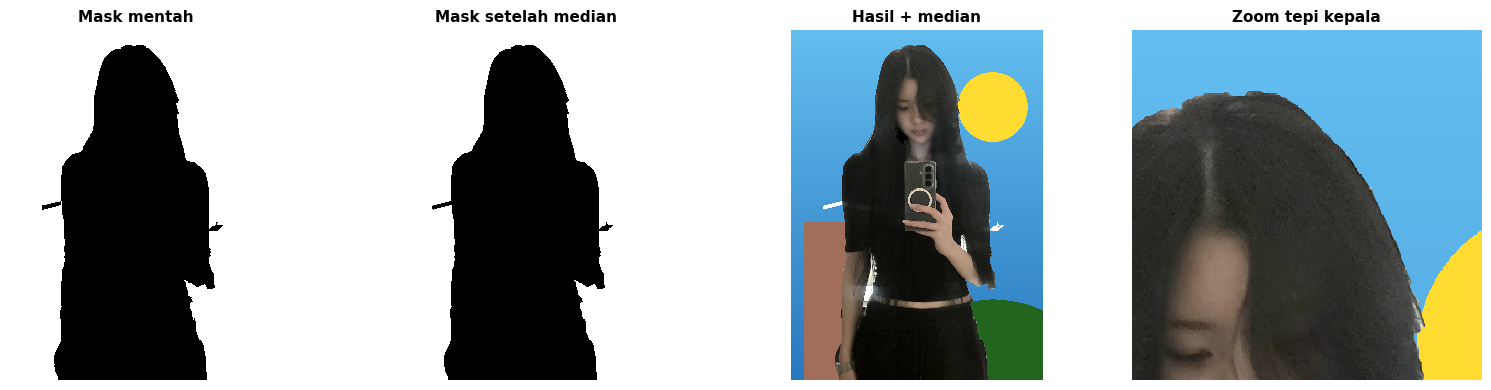

In [10]:
def median_biner(m, k=5):
    k = ganjil(k)
    putih = (m == 255).astype(np.float32)                   # [16] isi 0 atau 1
    jumlah = cv2.boxFilter(putih, -1, (k, k),
                           normalize=False,                 # [17]
                           borderType=cv2.BORDER_REPLICATE) # [18]
    return np.where(jumlah > (k * k) // 2, 255, 0).astype(np.uint8)   # [19] tulis dalam k


hasil_median = komposit_keras(frame, bg_img, mask_median)

# Area zoom otomatis: sekitar titik teratas subjek (biasanya kepala)
_, label, stat, _ = cv2.connectedComponentsWithStats(cv2.bitwise_not(mask_median), connectivity=8)
sisi = max(1, min(h, w) // 3)
if len(stat) > 1:
    utama = 1 + np.argmax(stat[1:, cv2.CC_STAT_AREA])
    atas = stat[utama, cv2.CC_STAT_TOP]
    xs = np.where(label[atas] == utama)[0]
    y0 = int(np.clip(atas - sisi // 4, 0, h - sisi))
    x0 = int(np.clip(xs[0] - sisi // 3, 0, w - sisi))
else:
    print('PERINGATAN: tidak ada area subjek di mask, zoom memakai bagian tengah. Periksa Tahap 1.')
    y0, x0 = (h - sisi) // 2, (w - sisi) // 2
y1, x1 = y0 + sisi, x0 + sisi   # boleh diubah manual kalau zoom-nya kurang pas

show([mask, mask_median, rgb(hasil_median), rgb(hasil_median[y0:y1, x0:x1])],
     ['Mask mentah', 'Mask setelah median', 'Hasil + median', 'Zoom tepi kepala'], cols=4)

In [11]:
lolos = True
# Cek Tahap 2
lolos &= cek(hitung_bintik(mask_median) <= hitung_bintik(mask),
             'bintik malah bertambah, periksa blank 10-15')
for k in (3, 5, 7):
    beda = np.count_nonzero(median_biner(mask, k) != cv2.medianBlur(mask, k))
    lolos &= cek(beda == 0,
                 f'k={k}: masih beda {beda} piksel dari cv2.medianBlur')
rng_cek = np.random.default_rng(0)
acak = (rng_cek.random((40, 50)) > 0.5).astype(np.uint8) * 255
lolos &= cek(np.array_equal(median_biner(acak, 5), cv2.medianBlur(acak, 5)),
             'gagal pada mask acak (cek penanganan tepi)')
print('Tahap 2 lolos'
      if lolos else 'Tahap 2 selesai dengan peringatan. Periksa pesan di atas dan lihat gambarnya.')

Tahap 2 lolos


---
## Tahap 3: Haluskan Tepi (Feathering)

Rumus alpha blending:
$$\text{hasil} = \alpha \cdot \text{subjek} + (1 - \alpha) \cdot \text{background}$$

**Hati-hati, ada tiga jebakan:**
1. $\alpha$ di rumus ini adalah bobot **subjek**. Bandingkan dengan konvensi `mask`-mu.
2. $\alpha$ harus bertipe float dengan rentang 0 sampai 1.
3. $\alpha$ berbentuk `(H, W)`, sedangkan citra `(H, W, 3)`. Keduanya harus bisa di-*broadcast*.

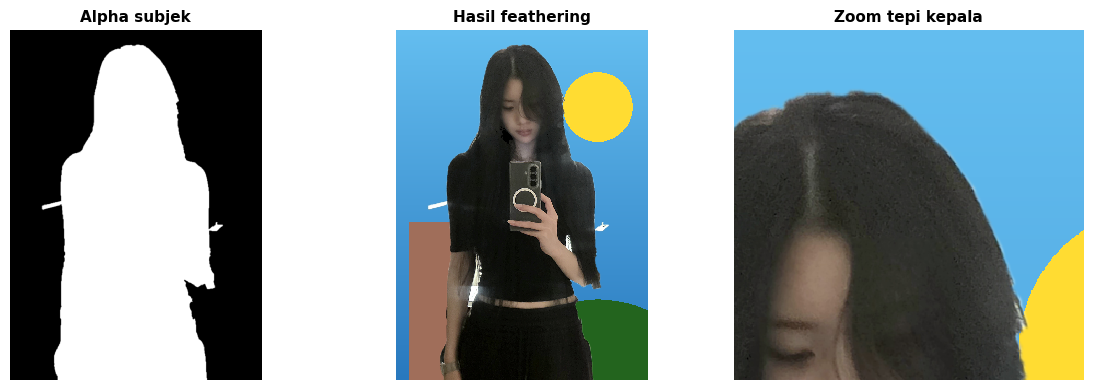

In [12]:
KSIZE = (7, 7)     # [20] ukuran kernel Gaussian (ada syaratnya!)
SIGMA = 1.5            # [21] eksperimen: 0.5 sampai 3


def buat_alpha(mask_bg, ksize, sigma):
    """Kembalikan alpha SUBJEK, float32, shape (H, W, 1), rentang 0..1."""
    ksize = tuple(0 if k <= 0 else ganjil(k) for k in ksize)
    sigma = max(float(sigma), 0.1)
    halus = cv2.GaussianBlur(mask_bg, ksize, sigma)         # [22]
    alpha = 1.0 - halus.astype(np.float32) / 255.0      # [23] [24]
    return alpha[..., None]                                 # [25]


def alpha_blend(subjek, bg, alpha):
    campur = alpha * subjek.astype(np.float32) + (1.0 - alpha) * bg.astype(np.float32)   # [26]
    return np.clip(np.rint(campur), 0, 255).astype(np.uint8)                         # [27] [28]


alpha = buat_alpha(mask_median, KSIZE, SIGMA)
hasil_feather = alpha_blend(frame, bg_img, alpha)

show([(alpha[..., 0] * 255).astype(np.uint8), rgb(hasil_feather), rgb(hasil_feather[y0:y1, x0:x1])],
     ['Alpha subjek', 'Hasil feathering', 'Zoom tepi kepala'])

In [13]:
lolos = True
# Cek Tahap 3
lolos &= cek(alpha.shape == (h, w, 1) and alpha.dtype == np.float32,
             'periksa shape atau dtype alpha')
lolos &= cek(alpha.min() >= 0 and alpha.max() <= 1,
             'alpha harus 0..1')
lolos &= cek(np.any((alpha > 0.05) & (alpha < 0.95)),
             'belum ada transisi halus di tepi')
dalam = cv2.erode(cv2.bitwise_not(mask_median), np.ones((15, 15), np.uint8)) == 255
luar = cv2.erode(mask_median, np.ones((15, 15), np.uint8)) == 255
if dalam.any() and luar.any():
    lolos &= cek(alpha[..., 0][dalam].mean() > 0.99, 'alpha di dalam subjek harus 1 (jebakan nomor 1)')
    lolos &= cek(alpha[..., 0][luar].mean() < 0.01, 'alpha di background harus 0')
lolos &= cek(dalam.any() and luar.any(),
             (f'Mask tidak punya area subjek/background yang cukup (background {np.mean(mask_median == 255):.1%}). ' \
    'Kembali ke Tahap 1 dan periksa latar serta batas HSV.'))
alpha_keras = ((mask_median == 0).astype(np.float32))[..., None]
lolos &= cek(np.array_equal(alpha_blend(frame, bg_img, alpha_keras), hasil_median),
             'dengan alpha biner, alpha_blend harus sama dengan komposit keras')
print('Tahap 3 lolos'
      if lolos else 'Tahap 3 selesai dengan peringatan. Periksa pesan di atas dan lihat gambarnya.')

Tahap 3 lolos


---
## Tahap 4: Bandingkan Tiga Hasil

Bandingkan secara visual (gambar penuh dan zoom), lalu secara angka:
- **Skor sampel**: persentase piksel benar di kotak latar dan kotak subjek.
- **Perubahan akibat feathering**: seberapa besar piksel berubah **di pita tepi** dibanding **di luar pita**. Angka ini menunjukkan *di mana* feathering bekerja, bukan seberapa bagus hasilnya. Penilaian bagus atau tidak tetap lewat matamu.

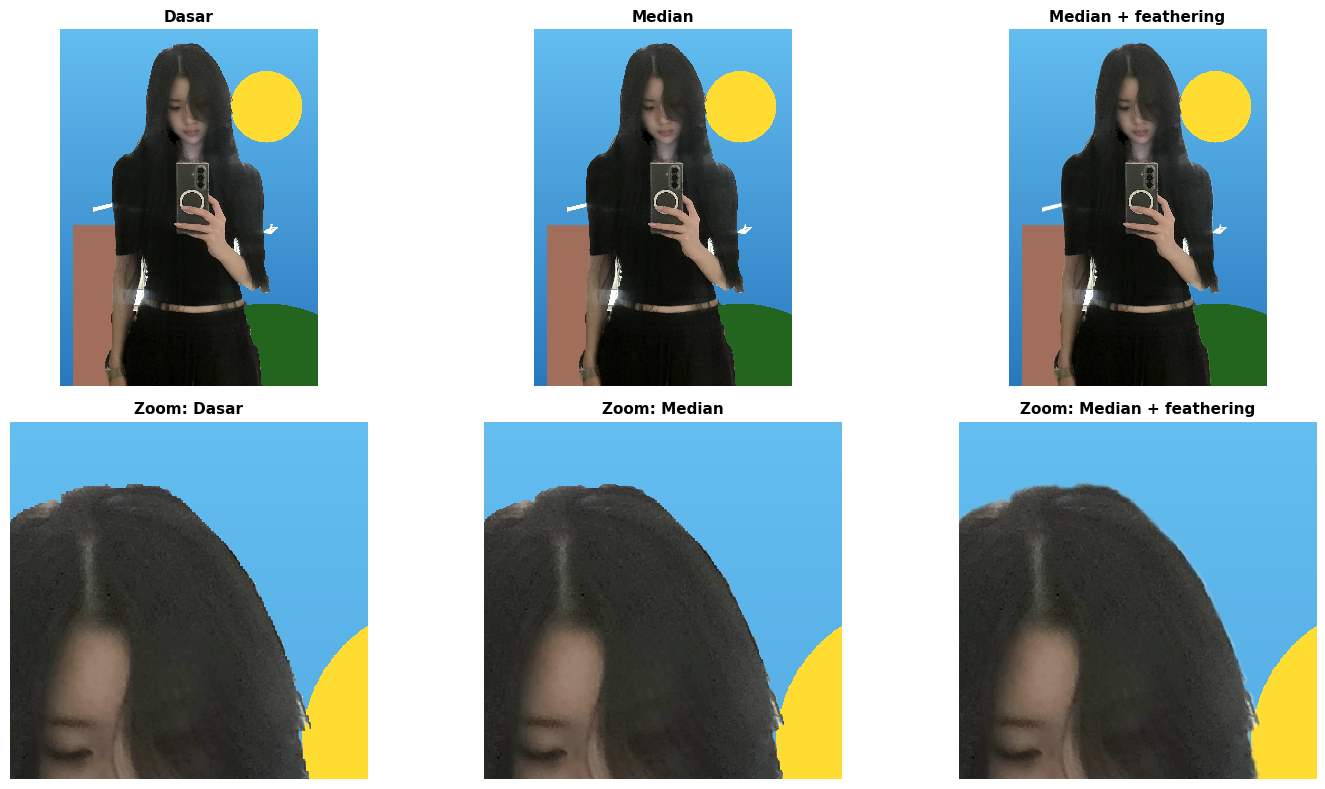

Mentah  sampel latar = 100.0% | sampel subjek = 100.0%
Median  sampel latar = 100.0% | sampel subjek = 100.0%
Perubahan di pita tepi : 6.80
Perubahan di luar pita : 0.00


In [14]:
nama = ['Dasar', 'Median', 'Median + feathering']
daftar = [hasil_dasar, hasil_median, hasil_feather]         # [29]
show([rgb(a) for a in daftar] + [rgb(a[y0:y1, x0:x1]) for a in daftar],
     nama + [f'Zoom: {n}' for n in nama], cols=3, size=(5, 4))   # [30] baris atas penuh, baris bawah zoom

for n, m in [('Mentah', mask), ('Median', mask_median)]:
    print(f'{n:7s} sampel latar = {skor_sampel(m)[0]:.1f}% | sampel subjek = {skor_sampel(m)[1]:.1f}%')

k_pita = np.ones((11, 11), np.uint8)
pita = cv2.dilate(mask_median, k_pita) != cv2.erode(mask_median, k_pita)   # [31] hanya daerah sekitar tepi
selisih = np.abs(hasil_feather.astype(np.float32) - hasil_median.astype(np.float32))   # [32] hindari wrap-around
for teks, area in [('di pita tepi ', pita), ('di luar pita ', ~pita)]:   # [33]
    nilai = f'{selisih[area].mean():.2f}' if area.any() else 'tidak ada piksel'
    print(f'Perubahan {teks}: {nilai}')

### 4.1 Eksperimen: parameter feathering

Coba beberapa nilai `sigma`. Amati kapan tepi masih bergerigi dan kapan mulai muncul *halo* hijau atau tepi tampak kabur.

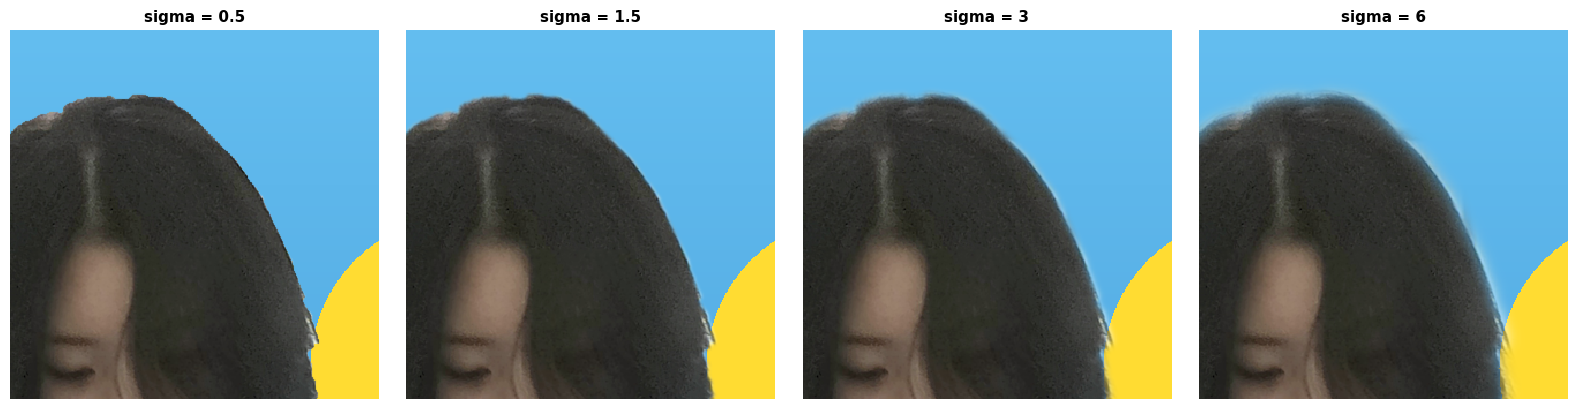

In [15]:
sigmas = [0.5, 1.5, 3, 6]
hasil_sigma = [alpha_blend(frame, bg_img, buat_alpha(mask_median, (0, 0), s)) for s in sigmas]  # [34] biar OpenCV hitung ukuran kernel dari sigma

show([rgb(a[y0:y1, x0:x1]) for a in hasil_sigma], [f'sigma = {s}' for s in sigmas], cols=4)

### 4.2 Analisis (jawab dengan kalimatmu sendiri)

1. Hasil mana yang paling natural, dan kenapa? Bagian mana yang membuatnya terlihat natural atau tidak?

   *Jawaban:*

2. Kenapa median lebih cocok daripada mean atau Gaussian untuk **membuang bintik** pada mask?

   *Jawaban:*

3. Kenapa Gaussian blur dilakukan **setelah** median? Apa yang terjadi pada bintik kalau urutannya dibalik dan mask tetap lembut?

   *Jawaban:*

4. Dari eksperimen sigma, apa yang dikorbankan kalau sigma terlalu besar? Dari mana warna pinggiran yang aneh itu berasal?

   *Jawaban:*

5. Setelah median, bintik pada mask hilang, tetapi kekasaran kontur (lihat Bonus) belum tentu mendekati 1. Apa risikonya kalau kernel median diperbesar untuk mengejar tepi yang lebih mulus?

   *Jawaban:*

### 4.3 Eksplorasi Gambar
Coba beberapa foto (ganti `FOTO_PATH`, sesuaikan kotak sampel dan batas HSV), lalu catat hasilnya.

| Foto | Batas HSV | Skor latar / subjek | Jumlah bintik mentah | Pengamatan |
|---|---|---|---|---|
| Latar hijau, cahaya rata | | | | |
| Latar hijau, ada bayangan | | | | |
| Latar biru | | | | |
| Subjek berambut halus atau terurai | | | | |
| Ada benda berwarna mirip latar | | | | |

**Kesimpulanmu:** foto seperti apa yang paling mudah dan paling sulit dipisahkan, dan kenapa?

*Jawaban:*

---
## Bonus: Seberapa Mulus Tepinya? (Canny)

Jalankan Canny pada **mask**, bukan pada foto. Tepi yang mulus menghasilkan garis tunggal yang rapi. Tepi kasar dan bintik menghasilkan banyak potongan tepi.

Untuk mengukur kekasaran kontur subjek, pakai rasio:
$$\text{kekasaran} = \frac{\text{keliling kontur terbesar}}{\text{keliling kontur setelah disederhanakan}}$$
Makin dekat ke 1, makin mulus.

Mentah  piksel tepi =   3242 | kekasaran kontur = 1.089
Median  piksel tepi =   3370 | kekasaran kontur = 1.047


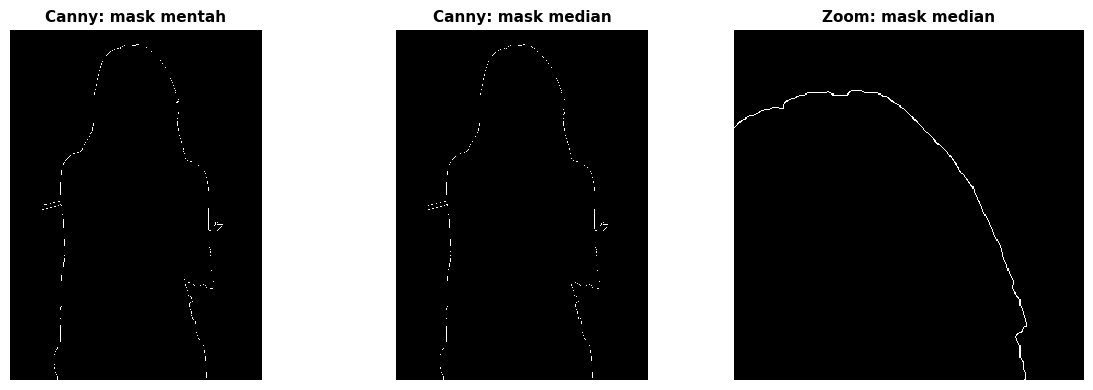

In [16]:
edge_mentah = cv2.Canny(mask, 50, 150)                      # [35]
edge_median = cv2.Canny(mask_median, 50, 150)


def kekasaran(mask_bg):
    subjek = cv2.bitwise_not(mask_bg)
    kontur, _ = cv2.findContours(subjek, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)      # [36] hanya kontur luar
    if not kontur:
        return float('nan')                                 # tidak ada subjek
    utama = max(kontur, key=cv2.contourArea)                # [37]
    sederhana = cv2.approxPolyDP(utama, 2.0, True)
    keliling = cv2.arcLength(sederhana, True)
    if keliling == 0:
        return float('nan')
    return cv2.arcLength(utama, True) / keliling                  # [38]


for n, m, e in [('Mentah', mask, edge_mentah), ('Median', mask_median, edge_median)]:
    print(f'{n:7s} piksel tepi = {np.count_nonzero(e):6d} | kekasaran kontur = {kekasaran(m):.3f}')   # [39]

show([edge_mentah, edge_median, edge_median[y0:y1, x0:x1]],
     ['Canny: mask mentah', 'Canny: mask median', 'Zoom: mask median'])

**Pertanyaan bonus:** kalau Canny dijalankan pada alpha hasil feathering dengan sigma besar, tepinya bisa berkurang atau bahkan hilang. Apakah itu berarti tepinya "lebih bagus"? Jelaskan dengan konsep gradien dan double threshold, lalu buktikan di sel di bawah.

*Jawaban:*

In [17]:
# Ruang eksperimenmu (tulis kode sendiri)